# Education Gap in the United States

## Research Question

### Importing Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
edgap = pd.read_excel("../data/EdGap_data.xlsx")

/opt/anaconda3/lib/python3.14/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


In [3]:
edgap.shape

(7986, 7)

In [4]:
edgap.head()

,NCESSCH School ID,CT Unemployment Rate,CT Pct Adults with College Degree,CT Pct Childre In Married Couple Family,CT Median Household Income,School ACT average (or equivalent if SAT score),School Pct Free and Reduced Lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


In [3]:
schools = pd.read_csv(
    "../data/ccd_sch_029_1617_w_1a_11212017.csv",
    encoding="latin1",
    dtype={"NCESSCH": "string"}
)

In [7]:
schools.shape

(102181, 23)

In [8]:
schools.head()

,SCHOOL_YEAR,STATENAME,ST,SCH_NAME,LEA_NAME,ST_LEAID,LEAID,ST_SCHID,NCESSCH,SCHID,...,MZIP,LSTREET1,LCITY,LSTATE,LZIP,UPDATED_STATUS_TEXT,EFFECTIVE_DATE,SCH_TYPE_TEXT,SCH_TYPE,LEVEL
0,2016-2017,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,AL-210,100002,AL-210-0020,10000200277,100277,...,35220,1000 Industrial School Road,Birmingham,AL,35220,Open,3/3/10,Alternative School,4,High
1,2016-2017,ALABAMA,AL,Camps,Alabama Youth Services,AL-210,100002,AL-210-0050,10000201667,101667,...,36057,1601 County Rd. 57,Prattville,AL,36067,Open,3/3/10,Alternative School,4,High
2,2016-2017,ALABAMA,AL,Det Ctr,Alabama Youth Services,AL-210,100002,AL-210-0060,10000201670,101670,...,36057,2109 Bashi Rd Bldg 509,Thomasville,AL,36784,Open,3/3/10,Alternative School,4,High
3,2016-2017,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,AL-210,100002,AL-210-0030,10000201705,101705,...,36057,1000 Industrial School Road,Mount Meigs,AL,36057,Open,3/3/10,Alternative School,4,High
4,2016-2017,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,AL-210,100002,AL-210-0040,10000201706,101706,...,35206,8950 Roebuck Blvd,Birmingham,AL,35206,Open,3/3/10,Alternative School,4,High


### Inspecting Datasets

In [9]:
edgap.info()

<class 'pandas.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   NCESSCH School ID                                7986 non-null   int64  
 1   CT Unemployment Rate                             7972 non-null   float64
 2   CT Pct Adults with College Degree                7973 non-null   float64
 3   CT Pct Childre In Married Couple Family          7961 non-null   float64
 4   CT Median Household Income                       7966 non-null   float64
 5   School ACT average (or equivalent if SAT score)  7986 non-null   float64
 6   School Pct Free and Reduced Lunch                7986 non-null   float64
dtypes: float64(6), int64(1)
memory usage: 436.9 KB


In [10]:
schools.info()

<class 'pandas.DataFrame'>
RangeIndex: 102181 entries, 0 to 102180
Data columns (total 23 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   SCHOOL_YEAR          102181 non-null  str   
 1   STATENAME            102181 non-null  str   
 2   ST                   102181 non-null  str   
 3   SCH_NAME             102181 non-null  str   
 4   LEA_NAME             102181 non-null  str   
 5   ST_LEAID             102181 non-null  str   
 6   LEAID                102181 non-null  int64 
 7   ST_SCHID             102181 non-null  str   
 8   NCESSCH              102181 non-null  string
 9   SCHID                102181 non-null  int64 
 10  MSTREET1             102181 non-null  str   
 11  MCITY                102181 non-null  str   
 12  MSTATE               102181 non-null  str   
 13  MZIP                 102181 non-null  int64 
 14  LSTREET1             102181 non-null  str   
 15  LCITY                102181 non-null  str   


### Clean and Prepare Duplicated Data 

In [12]:
edgap.duplicated().sum()

np.int64(0)

In [13]:
schools.duplicated().sum()

np.int64(0)

In [14]:
edgap.isnull().sum()

NCESSCH School ID                                   0
CT Unemployment Rate                               14
CT Pct Adults with College Degree                  13
CT Pct Childre In Married Couple Family            25
CT Median Household Income                         20
School ACT average (or equivalent if SAT score)     0
School Pct Free and Reduced Lunch                   0
dtype: int64

In [15]:
schools.isnull().sum()

SCHOOL_YEAR            0
STATENAME              0
ST                     0
SCH_NAME               0
LEA_NAME               0
ST_LEAID               0
LEAID                  0
ST_SCHID               0
NCESSCH                0
SCHID                  0
MSTREET1               0
MCITY                  0
MSTATE                 0
MZIP                   0
LSTREET1               0
LCITY                  0
LSTATE                 0
LZIP                   0
UPDATED_STATUS_TEXT    0
EFFECTIVE_DATE         0
SCH_TYPE_TEXT          0
SCH_TYPE               0
LEVEL                  0
dtype: int64

In [8]:
edgap_clean = edgap.dropna(
    subset=[
        "CT Unemployment Rate",
        "CT Pct Adults with College Degree",
        "CT Pct Childre In Married Couple Family",
        "CT Median Household Income"
    ]
).copy()

In [17]:
edgap_clean.shape

(7961, 7)

### Converting Data

In [18]:
edgap_clean.dtypes

NCESSCH School ID                                    int64
CT Unemployment Rate                               float64
CT Pct Adults with College Degree                  float64
CT Pct Childre In Married Couple Family            float64
CT Median Household Income                         float64
School ACT average (or equivalent if SAT score)    float64
School Pct Free and Reduced Lunch                  float64
dtype: object

### Merging Data
The variables were already formatted correctly. The school ID is an integer, and other variables, such as socioeconomic measures, ACT scores, and the percentage of students receiving free or reduced-price lunches, are stored as floating-point numbers. Now, we merge those datasets for further analysis.  

In [19]:
edgap_clean["NCESSCH School ID"].head()

0    100001600143
1    100008000024
2    100008000225
3    100017000029
4    100018000040
Name: NCESSCH School ID, dtype: int64

In [20]:
schools["NCESSCH"].head()

0    10000200277
1    10000201667
2    10000201670
3    10000201705
4    10000201706
Name: NCESSCH, dtype: string

In [21]:
edgap_ids = set(edgap_clean["NCESSCH School ID"].astype(str))
school_ids = set(schools["NCESSCH"].dropna())

print("Exact matches:", len(edgap_ids.intersection(school_ids)))
print("Matches after adding a leading zero:", 
      len(edgap_ids.intersection({"0" + x for x in school_ids if len(x) == 11})))

Exact matches: 0
Matches after adding a leading zero: 0


In [22]:
edgap_clean["NCESSCH School ID"].astype(str).str.len().value_counts()

NCESSCH School ID
12    7961
Name: count, dtype: int64

In [23]:
schools["NCESSCH"].str.len().value_counts()

NCESSCH
11    93503
10     7700
9       624
7       295
8        31
5        28
Name: count, dtype: Int64

In [24]:
print("EdGap first ID:", str(edgap_clean["NCESSCH School ID"].iloc[0]))
print("School first ID:", schools["NCESSCH"].iloc[0])

EdGap first ID: 100001600143
School first ID: 10000200277


In [25]:
schools[["ST_LEAID", "SCHID", "NCESSCH"]].head(10)

,ST_LEAID,SCHID,NCESSCH
0,AL-210,100277,10000200277
1,AL-210,101667,10000201667
2,AL-210,101670,10000201670
3,AL-210,101705,10000201705
4,AL-210,101706,10000201706
5,AL-210,101876,10000201876
6,AL-101,100870,10000500870
7,AL-101,100871,10000500871
8,AL-101,100879,10000500879
9,AL-101,100889,10000500889


In [26]:
edgap_clean["NCESSCH School ID"].head(10)

0     100001600143
1     100008000024
2     100008000225
3     100017000029
4     100018000040
5     100019000050
7     100020000239
8     100020000240
9     100023000209
10    100027000080
Name: NCESSCH School ID, dtype: int64

In [5]:
schools["NCESSCH_fixed"] = (
    schools["NCESSCH"].str[:7] +
    schools["NCESSCH"].str[7:].str.zfill(5)
)

In [6]:
schools[["NCESSCH", "NCESSCH_fixed"]].head(10)

,NCESSCH,NCESSCH_fixed
0,10000200277,100002000277
1,10000201667,100002001667
2,10000201670,100002001670
3,10000201705,100002001705
4,10000201706,100002001706
5,10000201876,100002001876
6,10000500870,100005000870
7,10000500871,100005000871
8,10000500879,100005000879
9,10000500889,100005000889


In [9]:
print(edgap_clean["NCESSCH School ID"].head())
print(schools["NCESSCH"].head())

0    100001600143
1    100008000024
2    100008000225
3    100017000029
4    100018000040
Name: NCESSCH School ID, dtype: int64
0    10000200277
1    10000201667
2    10000201670
3    10000201705
4    10000201706
Name: NCESSCH, dtype: string


In [23]:
education.to_csv("../data/education_merged.csv", index=False)

### Derived Variables

In [25]:
education["frpl_percentage"] = (
    education["school_pct_free_and_reduced_lunch"] * 100
)

In [26]:
education[
    [
        "school_pct_free_and_reduced_lunch",
        "frpl_percentage"
    ]
].head()

,school_pct_free_and_reduced_lunch,frpl_percentage
0,0.066901,6.690141
1,0.112412,11.241218
2,0.096816,9.681611
3,0.296960,29.696025
4,0.262641,26.264114


In [27]:
education.to_csv(
    "../data/education_prepared.csv",
    index=False
)


### Statistics 

In [29]:
analysis_data = education[
    [
        "school_act_average_or_equivalent_if_sat_score",
        "frpl_percentage",
        "ct_unemployment_rate",
        "ct_pct_adults_with_college_degree",
        "ct_median_household_income"
    ]
]

In [30]:
analysis_data.describe()

,school_act_average_or_equivalent_if_sat_score,frpl_percentage,ct_unemployment_rate,ct_pct_adults_with_college_degree,ct_median_household_income
count,7961.000000,7961.000000,7961.000000,7961.000000,7961.00000
mean,20.180535,42.054986,0.098548,0.568865,52040.46464
std,2.592721,23.978616,0.058458,0.165494,24220.42439
min,-3.070818,-5.454545,0.000000,0.091493,3589.00000
25%,18.600000,23.843416,0.058653,0.450850,36612.00000
50%,20.400000,38.125000,0.085603,0.554979,46844.00000
75%,21.910867,57.520786,0.123288,0.676433,61375.00000
max,32.362637,99.872881,0.576125,1.000000,226181.00000


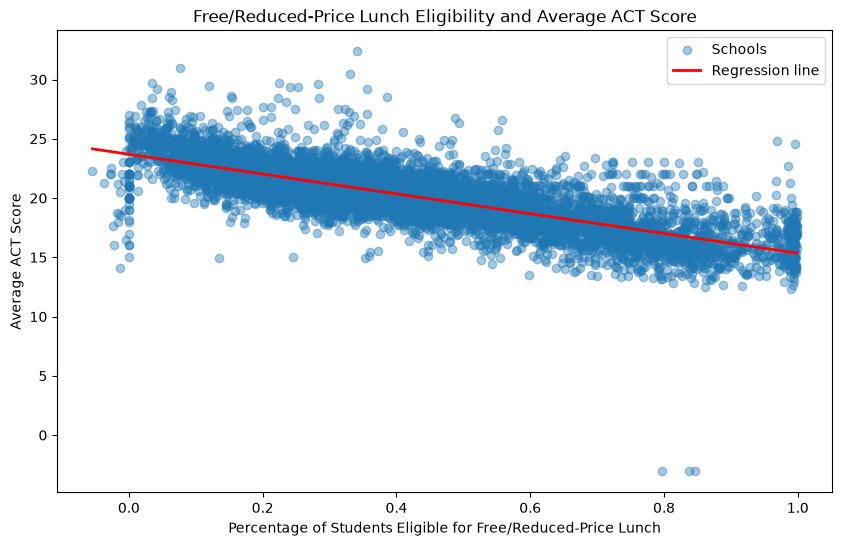

In [34]:
import numpy as np
import matplotlib.pyplot as plt

x = edgap_clean["School Pct Free and Reduced Lunch"]
y = edgap_clean["School ACT average (or equivalent if SAT score)"]

slope, intercept = np.polyfit(x, y, 1)

x_line = np.linspace(x.min(), x.max(), 100)
y_line = slope * x_line + intercept

plt.figure(figsize=(10, 6))
plt.scatter(x, y, alpha=0.4, label="Schools")
plt.plot(x_line, y_line, color="red", linewidth=2, label="Regression line")

plt.xlabel("Percentage of Students Eligible for Free/Reduced-Price Lunch")
plt.ylabel("Average ACT Score")
plt.title("Free/Reduced-Price Lunch Eligibility and Average ACT Score")
plt.legend()
plt.show()

In [36]:
edgap_clean[
    [
        "School ACT average (or equivalent if SAT score)",
        "School Pct Free and Reduced Lunch",
        "CT Unemployment Rate",
        "CT Pct Adults with College Degree",
        "CT Median Household Income"
    ]
].describe()

,School ACT average (or equivalent if SAT score),School Pct Free and Reduced Lunch,CT Unemployment Rate,CT Pct Adults with College Degree,CT Median Household Income
count,7961.000000,7961.000000,7961.000000,7961.000000,7961.00000
mean,20.180535,0.420550,0.098548,0.568865,52040.46464
std,2.592721,0.239786,0.058458,0.165494,24220.42439
min,-3.070818,-0.054545,0.000000,0.091493,3589.00000
25%,18.600000,0.238434,0.058653,0.450850,36612.00000
50%,20.400000,0.381250,0.085603,0.554979,46844.00000
75%,21.910867,0.575208,0.123288,0.676433,61375.00000
max,32.362637,0.998729,0.576125,1.000000,226181.00000


In [37]:
correlation_data = edgap_clean[
    [
        "School ACT average (or equivalent if SAT score)",
        "School Pct Free and Reduced Lunch",
        "CT Unemployment Rate",
        "CT Pct Adults with College Degree",
        "CT Median Household Income"
    ]
]

correlation_data.corr().round(3)

,School ACT average (or equivalent if SAT score),School Pct Free and Reduced Lunch,CT Unemployment Rate,CT Pct Adults with College Degree,CT Median Household Income
School ACT average (or equivalent if SAT score),1.000,-0.772,-0.433,0.442,0.453
School Pct Free and Reduced Lunch,-0.772,1.000,0.477,-0.445,-0.502
CT Unemployment Rate,-0.433,0.477,1.000,-0.414,-0.487
CT Pct Adults with College Degree,0.442,-0.445,-0.414,1.000,0.707
CT Median Household Income,0.453,-0.502,-0.487,0.707,1.000


In [39]:
import numpy as np
from scipy.stats import linregress

x = edgap_clean["School Pct Free and Reduced Lunch"]
y = edgap_clean["School ACT average (or equivalent if SAT score)"]

results = linregress(x, y)

print("Slope:", results.slope)
print("Intercept:", results.intercept)
print("Correlation (r):", results.rvalue)
print("R-squared:", results.rvalue**2)
print("P-value:", results.pvalue)

Slope: -8.350109256460632
Intercept: 23.6921723165637
Correlation (r): -0.7722544324828734
R-squared: 0.5963769084894449
P-value: 0.0


In [40]:
import pandas as pd

regression_summary = pd.DataFrame({
    "Statistic": [
        "Slope",
        "Intercept",
        "Correlation (r)",
        "R-squared",
        "P-value"
    ],
    "Value": [
        results.slope,
        results.intercept,
        results.rvalue,
        results.rvalue**2,
        results.pvalue
    ]
})

regression_summary["Value"] = regression_summary["Value"].round(4)

regression_summary

,Statistic,Value
0,Slope,-8.3501
1,Intercept,23.6922
2,Correlation (r),-0.7723
3,R-squared,0.5964
4,P-value,0.0000


### Regression Result

The results above show a strong negative relationship between the percentage of students eligible for free or reduced-price lunch and average ACT scores (r) = -0.77. The regression slope was -8.35, which means that higher lunch eligibility was associated with lower ACT scores. The data had an R squared value of 0.596, meaning that about 59.64% of the variation in average ACT scores was explained by the linear relationship with lunch eligibility. The p-value was reported as 0, which indicates strong statistical evidence. However, this analysis identifies an association and does not establish that lunch eligibility causes lower ACT scores.

### Conclusion

This analysis suggests that schools with higher percentages of students eligible for free or reduced-price lunch tend to have lower average ACT scores. This relationship may reflect extensive socioeconomic differences between schools, but the analysis does not prove causation. Future research could examine additional factors, such as school location (rural vs. urban), student demographics, and access to academic resources, to better understand differences in ACT performance.

In [43]:
education.to_csv("../data/education_prepared.csv", index=False)
print("Prepared dataset exported successfully.")

Prepared dataset exported successfully.
